# Lab Regressions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
import re
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
from regression_functions import *

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Read in clean lab data

In [2]:
labs_clean = pd.read_csv("../data/clincal_chems_abx_users_clean.csv")

In [3]:
labs_clean.public_client_id.nunique()

2351

In [4]:
statin_users = pd.read_csv('../data/arivale_statin_users.csv', dtype={"public_client_id":str, "days_in_program":float})
statin_users = statin_users.sort_values(by="days_in_program")
labs_clean = labs_clean.sort_values(by="days_in_program")

# Merge with all
labs_clean_statin = pd.merge_asof(
    labs_clean, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

labs_clean_statin.loc[:,'statin_binary'] = labs_clean_statin.loc[:,'statin'].notna().astype(int)

In [5]:
# 1. Remove the column and save its data
col_to_move = labs_clean_statin.pop('statin_binary')

# 2. Insert it back at index 30 (Position 31)
labs_clean_statin.insert(22, 'statin_binary', col_to_move)

In [6]:
labs_clean_statin.columns[0:33]

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol',
       'abx_recency', 'sex', 'age', 'BMI_CALC', 'hx_t2dm', 'hx_gestational',
       'gluc_dysreg', 'eGFR', 'centered_eGFR', 'centered_BMI',
       'abx_recency_three', 'abx_recency_twelve', 'vendor', 'statin_binary',
       'vendor_observation_id', 'observation_id', 'reflexive', 'fasting',
       'days_since_first_call', 'days_since_first_draw', 'month', 'weekday',
       'season', 'A_GRATIO'],
      dtype='object')

In [7]:
labs_mma_small = labs_clean_statin[['public_client_id', 'days_in_program', 'abx_recency', 'hx_t2dm', 'hx_gestational',
                                    'gluc_dysreg', 'vendor', 'HOMOCYSTEINE_SERUM', 'METHYLMALONICACID',
                                    'VITAMIND3_25_OH', 'GLYCOHEMOGLOBINA1C']]

In [8]:
# labs_mma_small.to_csv("../data/abx_cohort_labs_glucose_dysreg_hx.csv", index=False)

In [9]:
labs_clean_statin.drop(columns=['statin', 'dosage', 'medications_free_text'], inplace=True)

In [10]:
lab_features = labs_clean_statin.columns[32:]

## Identify which clinical chemistry tests were offered by each vendor

In [11]:
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

**Not offered by Quest: Lapcorp only tests**

In [12]:
quest[lab_features].isna().all().sum()

8

In [13]:
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()

In [14]:
not_offered_quest

['DPA',
 'HDLPARTICLENUMBER',
 'LINOLEIC_ACID',
 'LPIR_SCORE',
 'MAGNESIUM_SERUM',
 'OMEGA_3_TOTAL',
 'OMEGA_6_TOTAL',
 'OXLDL']

**Not offered by labcorp: Quest only tests**

In [15]:
labcorp[lab_features].isna().all().sum()

16

In [16]:
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()

In [17]:
not_offered_labcorp

['ANTIOXIDCAP_TOTAL',
 'ARSENIC_BLOOD',
 'BILIRUBIN_DIRECT',
 'BILIRUBIN_INDIRECT',
 'COPPER_RBC',
 'HDLLARGE',
 'LACTICDEHYDROGENASE',
 'LDLMEDIUM',
 'MANGANESE_SERUM',
 'MPV',
 'PAI_1ANTIGEN_QNT',
 'PHOSPHORUSINORGANIC',
 'SELENIUM_SERUM',
 'SUPEROXDISMUTSOD',
 'VITAMIND3_25_OH',
 'ZINC_RBC']

**Offered by both vendors**

In [18]:
individual_vendors = not_offered_labcorp + not_offered_quest

In [19]:
shared_labs = list(set(lab_features) - set(individual_vendors))

# Perform Regressions
Remember, we should test the vendor specific tests separately and then concatenate tables and FDR correct at the end.

In [20]:
len(shared_labs)

70

In [21]:
# shared_labs

In [22]:
len(not_offered_labcorp) # Quest specific

16

In [23]:
# not_offered_labcorp

In [24]:
len(not_offered_quest) # LCA specific

8

In [25]:
# not_offered_quest

## Unadjusted (Model 1)
Here we are just adjusting for batch effects due to vendor. 

In [26]:
forumla_unadjusted_vendor = "{feature} ~ C(abx_recency) + vendor" # This is so I can do the shared labs
forumla_unadjusted = "{feature} ~ C(abx_recency)"
abx_term_three = "C(abx_recency)[T.three]"
abx_term_twelve = "C(abx_recency)[T.twelve]"

### Unadjusted: 3 month group

In [27]:
tests_abx_three_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_three)
tests_abx_three_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_three)
tests_abx_three_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_three)

# Concat
tests_three = pd.concat([tests_abx_three_shared, tests_abx_three_quest, tests_abx_three_labcorp])

# Apply FDR correctly since we concatenated 3 tables
tests_three.drop(columns='q', inplace=True) 
tests_three.loc[:, "q"] = multipletests(tests_three.p, method="fdr_bh")[1]
tests_three.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
INSULIN,INSULIN,1.234990,0.533053,2.316823,0.189686,2.280294,0.020599,2351.0,0.341236
IL_6,IL_6,2.143770,0.840919,2.549317,0.494720,3.792819,0.010859,2278.0,0.341236
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.038335,0.017140,-2.236522,-0.071947,-0.004723,0.025411,2351.0,0.341236
POTASSIUM,POTASSIUM,-0.041579,0.017828,-2.332194,-0.076540,-0.006618,0.019775,2351.0,0.341236
PLATELETCOUNTTHOUSAND,PLATELETCOUNTTHOUSAND,9.157966,3.307052,2.769224,2.672897,15.643035,0.005663,2336.0,0.341236


### Unadjusted: 12 months

In [28]:
tests_abx_twelve_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_twelve)
tests_abx_twelve_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_twelve)
tests_abx_twelve_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_twelve)

# Concat
tests_twelve = pd.concat([tests_abx_twelve_shared, tests_abx_twelve_quest, tests_abx_twelve_labcorp])

# Apply FDR
tests_twelve.drop(columns='q', inplace=True) 
tests_twelve.loc[:, "q"] = multipletests(tests_twelve.p, method="fdr_bh")[1]
tests_twelve.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
QUICKI,QUICKI,-0.007722,0.001821,-4.239910,-0.011294,-0.004151,0.000023,2351.0,0.002183
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.050003,0.015203,-3.289000,-0.079816,-0.020190,0.001020,2351.0,0.047954
TRIGLYCERIDES,TRIGLYCERIDES,7.835424,3.013475,2.600129,1.926072,13.744776,0.009377,2350.0,0.124717
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.019017,0.006683,2.845782,0.005913,0.032122,0.004469,2335.0,0.124717
INSULIN,INSULIN,1.255982,0.472807,2.656437,0.328819,2.183145,0.007951,2351.0,0.124717


## Adjusted full model
This does not account for t2dm or gestational diabetes

In [29]:
forumla_full_vendor = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")
forumla_full = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")

### 3 months

In [30]:
tests_abx_three_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_three)
tests_abx_three_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_three)
tests_abx_three_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_three)

# Concat
tests_three_full = pd.concat([tests_abx_three_shared_full, tests_abx_three_quest_full, tests_abx_three_labcorp_full])

# FDR correct
tests_three_full.drop(columns='q', inplace=True) 
tests_three_full.loc[:, "q"] = multipletests(tests_three_full.p, method="fdr_bh")[1]
tests_three_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.276506,0.110222,2.508621,0.060361,0.492651,0.012188,2335.0,0.728246
IL_6,IL_6,2.051305,0.846792,2.422443,0.390735,3.711874,0.015495,2278.0,0.728246
PLATELETCOUNTTHOUSAND,PLATELETCOUNTTHOUSAND,5.819515,3.086218,1.885646,-0.232517,11.871548,0.059467,2336.0,0.931657
VITAMIND_25_OHTOT,VITAMIND_25_OHTOT,1.598314,0.792403,2.017046,0.044427,3.152201,0.043805,2350.0,0.931657
SODIUM,SODIUM,-0.231298,0.117829,-1.962997,-0.462359,-0.000238,0.049765,2351.0,0.931657


### 12 months

In [31]:
tests_abx_twelve_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_twelve)
tests_abx_twelve_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_twelve)
tests_abx_twelve_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_twelve)

# Concat
tests_twelve_full = pd.concat([tests_abx_twelve_shared_full, tests_abx_twelve_quest_full, tests_abx_twelve_labcorp_full])

# FDR correct
tests_twelve_full.drop(columns='q', inplace=True) 
tests_twelve_full.loc[:, "q"] = multipletests(tests_twelve_full.p, method="fdr_bh")[1]
tests_twelve_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.014603,0.006476,2.255002,0.001904,0.027302,0.024226,2335.0,0.625683
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015210,0.007125,-2.134775,-0.029210,-0.001211,0.033281,498.0,0.625683
MONOCYTES,MONOCYTES,0.238852,0.097035,2.461511,0.048568,0.429136,0.013908,2335.0,0.625683
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.037965,0.014515,-2.615672,-0.066428,-0.009503,0.008963,2351.0,0.625683
QUICKI,QUICKI,-0.003118,0.001412,-2.209110,-0.005886,-0.000350,0.027264,2351.0,0.625683


In [32]:
# For supplement:
tests_three_full.to_csv("../data/chemistries_regressions_all_three.csv")
tests_twelve_full.to_csv("../data/chemistries_regressions_all_twelve.csv")

## Model 3: Now account for history of T2DM or Gestational Diabetes
No interaction term yet!

In [33]:
forumla_hx_vendor = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor + C(hx_t2dm) + C(hx_gestational)")
forumla_hx = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(hx_t2dm) + C(hx_gestational)")

## Three months

In [34]:
tests_abx_three_shared_hx = run_tests(shared_labs, labs_clean, forumla_hx_vendor, abx_term_three)
tests_abx_three_quest_hx= run_tests(list(not_offered_labcorp), labs_clean, forumla_hx, abx_term_three)
tests_abx_three_labcorp_hx= run_tests(list(not_offered_quest), labs_clean, forumla_hx, abx_term_three)

# Concat
tests_three_hx= pd.concat([tests_abx_three_shared_hx, tests_abx_three_quest_hx, tests_abx_three_labcorp_hx])

# FDR correct
tests_three_hx.drop(columns='q', inplace=True) 
tests_three_hx.loc[:, "q"] = multipletests(tests_three_hx.p, method="fdr_bh")[1]
tests_three_hx.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.270986,0.110176,2.459560,0.054931,0.487040,0.013983,2335.0,0.754362
IL_6,IL_6,2.043551,0.848094,2.409582,0.380428,3.706675,0.016050,2278.0,0.754362
CHLORIDE,CHLORIDE,-0.075689,0.129830,-0.582991,-0.330283,0.178904,0.559956,2351.0,0.945080
CRPHIGHSENSITIVITY,CRPHIGHSENSITIVITY,-0.405788,0.283841,-1.429631,-0.962396,0.150819,0.152957,2351.0,0.945080
HDLCHOLDIRECT,HDLCHOLDIRECT,-0.828437,0.886433,-0.934574,-2.566715,0.909841,0.350105,2350.0,0.945080


## Twelve months

In [35]:
tests_abx_twelve_shared_hx = run_tests(shared_labs, labs_clean, forumla_hx_vendor, abx_term_twelve)
tests_abx_twelve_quest_hx = run_tests(list(not_offered_labcorp), labs_clean, forumla_hx, abx_term_twelve)
tests_abx_twelve_labcorp_hx = run_tests(list(not_offered_quest), labs_clean, forumla_hx, abx_term_twelve)

# Concat
tests_twelve_hx = pd.concat([tests_abx_twelve_shared_hx, tests_abx_twelve_quest_hx, tests_abx_twelve_labcorp_hx])

# FDR correct
tests_twelve_hx.drop(columns='q', inplace=True) 
tests_twelve_hx.loc[:, "q"] = multipletests(tests_twelve_hx.p, method="fdr_bh")[1]
tests_twelve_hx.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.013966,0.006458,2.162600,0.001302,0.026630,0.030674,2335.0,0.738799
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015242,0.007167,-2.126602,-0.029324,-0.001159,0.033961,498.0,0.738799
MONOCYTES,MONOCYTES,0.228333,0.097098,2.351569,0.037925,0.418741,0.018778,2335.0,0.738799
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.037908,0.014539,-2.607313,-0.066418,-0.009397,0.009184,2351.0,0.738799
QUICKI,QUICKI,-0.002901,0.001407,-2.062214,-0.005659,-0.000142,0.039298,2351.0,0.738799


# Model 4: Interaction term with history of T2DM
I am still adjusting for a history of gestational diabetes and current blood sugar lowering medication use.

In [36]:
forumla_gintv = ("{feature} ~ C(abx_recency)*C(hx_t2dm) + BMI_CALC + sex + age + C(meds_cholesterol) + C(meds_blood_sugar)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor + C(hx_gestational)")
forumla_gint = ("{feature} ~ C(abx_recency)*C(hx_t2dm) + BMI_CALC + sex + age + C(meds_cholesterol) + C(meds_blood_sugar)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + + C(hx_gestational)")

gint_three = "C(abx_recency)[T.three]:C(hx_t2dm)[T.Yes]"
gint_twelve = "C(abx_recency)[T.twelve]:C(hx_t2dm)[T.Yes]"

In [37]:
tests_abx_three_shared_gint = run_tests(shared_labs, labs_clean, forumla_gintv, gint_three)
tests_abx_three_quest_gint = run_tests(list(not_offered_labcorp), labs_clean, forumla_gint, gint_three)
tests_abx_three_labcorp_gint = run_tests(list(not_offered_quest), labs_clean, forumla_gint, gint_three)

# Concat
tests_three_gint = pd.concat([tests_abx_three_shared_gint, tests_abx_three_quest_gint, tests_abx_three_labcorp_gint])

# FDR correct
tests_three_gint.drop(columns='q', inplace=True) 
tests_three_gint.loc[:, "q"] = multipletests(tests_three_gint.p, method="fdr_bh")[1]
tests_three_gint.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
METHYLMALONICACID,METHYLMALONICACID,137.253514,27.973235,4.906601,82.398037,192.108990,9.917526e-07,2313.0,0.000093
HOMOCYSTEINE_SERUM,HOMOCYSTEINE_SERUM,2.854356,0.803601,3.551957,1.278508,4.430204,3.899761e-04,2346.0,0.012863
ALKALINEPHOSPHATASE,ALKALINEPHOSPHATASE,19.298572,5.454144,3.538332,8.603094,29.994050,4.105341e-04,2351.0,0.012863
ALAT_SGPT_,ALAT_SGPT_,-10.425781,3.812263,-2.734801,-17.901560,-2.950003,6.289015e-03,2351.0,0.147792
VITAMIND_25_OHTOT,VITAMIND_25_OHTOT,-9.840124,3.962742,-2.483160,-17.610991,-2.069257,1.309209e-02,2350.0,0.246131


In [38]:
tests_abx_twelve_shared_gint = run_tests(shared_labs, labs_clean, forumla_gintv, gint_twelve)
tests_abx_twelve_quest_gint = run_tests(list(not_offered_labcorp), labs_clean, forumla_gint, gint_twelve)
tests_abx_twelve_labcorp_gint = run_tests(list(not_offered_quest), labs_clean, forumla_gint, gint_twelve)

# Concat
tests_twelve_gint = pd.concat([tests_abx_twelve_shared_gint, tests_abx_twelve_quest_gint, tests_abx_twelve_labcorp_gint])

# FDR correct
tests_twelve_gint.drop(columns='q', inplace=True) 
tests_twelve_gint.loc[:, "q"] = multipletests(tests_twelve_gint.p, method="fdr_bh")[1]
tests_twelve_gint.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MCH,MCH,0.809649,0.455762,1.776474,-0.084094,1.703393,0.075786,2337.0,0.704229
MCHC,MCHC,0.405202,0.221985,1.825356,-0.030108,0.840511,0.068076,2337.0,0.704229
ANTIOXIDCAP_TOTAL,ANTIOXIDCAP_TOTAL,461.374554,235.783257,1.956774,-1.922773,924.671881,0.050955,497.0,0.704229
REDCELLCOUNT,REDCELLCOUNT,-0.197458,0.089422,-2.208159,-0.372813,-0.022103,0.027331,2337.0,0.704229
ARACHIDONICACID,ARACHIDONICACID,0.884906,0.482335,1.834629,-0.060953,1.830764,0.066690,2312.0,0.704229


In [39]:
# For supplement:
tests_three_gint.to_csv("../data/chemistries_regressions_interaction_three.csv")
tests_twelve_gint.to_csv("../data/chemistries_regressions_interaction_twelve.csv")

In [38]:
sns.set_style(style="whitegrid",  rc={"xtick.bottom": True, 'ytick.left': True})
sig_cols = ['METHYLMALONICACID',
            'HOMOCYSTEINE_SERUM',
            'ALKALINEPHOSPHATASE']
abx_order=['none','twelve','three']
markers_order=['o', 's', 'D']
legend_labels = {'none': 'None','three': '0 - 3 months','twelve': '3 - 12 months'}
line_order = ["-","-","--"]

# Make 3 month a little darker for the lineplot specifically
lp_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#B9CACC'} 

In [39]:
# sns.pointplot(data=labs_clean_statin, x='hx_t2dm', y='ALKALINEPHOSPHATASE', hue='abx_recency')

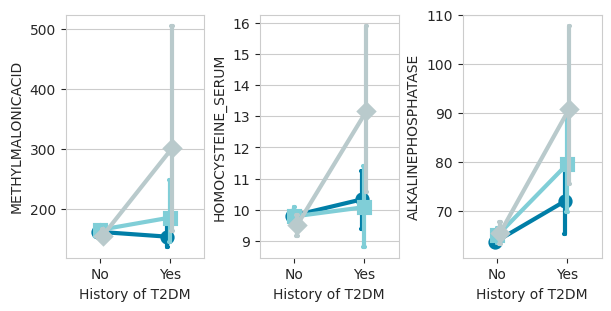

In [40]:
# Create subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(6, 3), constrained_layout=True)  
axes = axes.flatten()

# Loop through each column and create a subplot
for i, col in enumerate(sig_cols):
    ax = axes[i]
    sns.pointplot(data=labs_clean, x='hx_t2dm', y=col, hue='abx_recency',
                  hue_order=abx_order, palette=lp_pal, linewidth=3, # linestyles=line_order
                  markers=markers_order, errorbar=('ci', 95), n_boot=1000,
                  ax=ax, capsize=0.02, ms=8, dodge=0.07)
    ax.set_xlabel('History of T2DM')
    # ax.set_ylabel('')

for ax in axes:
    ax.legend_.remove()
    
plt.savefig("../figures/t2dm_abx_interaction_lineplots.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [46]:
check_unit = adi.get_snapshot('chemistries_metadata')

In [61]:
# check_unit[check_unit['Name'].isin(
#     ['METHYLMALONIC ACID', 'HOMOCYSTEINE, SERUM', 'ALKALINE PHOSPHATASE']
# )]

## Look at metformin usage re: MMA hit

In [91]:
check_meds = adi.get_snapshot('assessments_medications')[[
    'public_client_id','days_in_program','assessment_vitals_prescriptions_text'
]].copy()

In [92]:
metformin_pat = re.compile(
    r"""
    \b(?:
        met\s?a?\s?(?:f|ph)ormin       # metformin, metaformin, met formin, metphormin
      | glucophage(?:\s*xr)?
      | glumetza | fortamet | riomet
      # ---- fixed-dose combos that CONTAIN metformin ----
      | janumet(?:\s*xr)?
      | kombiglyze(?:\s*xr)?
      | jentadueto(?:\s*xr)?
      | invokamet(?:\s*xr)?
      | synjardy(?:\s*xr)?
      | xigduo(?:\s*xr)?
      | segluromet
      | trijardy(?:\s*xr)?
      | actoplus\s*met
      | prandimet
      | glucovance
      | metaglip
      | kazano
    )\b
    """,
    re.IGNORECASE | re.VERBOSE,
)

In [93]:
check_meds.set_index('public_client_id', inplace=True)

In [94]:
mask = check_meds['assessment_vitals_prescriptions_text'].fillna("").str.contains(metformin_pat)

In [95]:
mask.sum()

220

In [101]:
metformin_ids = mask[mask].index.tolist()

In [103]:
labs_clean['metformin'] = labs_clean['public_client_id'].apply(lambda x: "Yes" if x in metformin_ids else "No")

In [105]:
labs_clean['metformin'].value_counts()

metformin
No     2272
Yes      79
Name: count, dtype: int64

In [106]:
# Should look to see if metformin use if driving the low MMA
mma_metformin_abx = ('METHYLMALONICACID ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) +'
                    'C(hx_t2dm)*C(abx_year) + C(meds_blood_sugar) + C(hx_t2dm) + C(hx_gestational) + C(metformin)')

mma_metformin_model = ols(mma_metformin_abx, data=labs_clean).fit()
mma_metformin_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      METHYLMALONICACID   R-squared:                       0.096
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     15.19
Date:                Tue, 04 Aug 2026   Prob (F-statistic):           2.86e-40
Time:                        15:00:39   Log-Likelihood:                -13677.
No. Observations:                2313   AIC:                         2.739e+04
Df Residuals:                    2296   BIC:                         2.749e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
==============================================================================================================
                                                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                    156.3508     12.730     12.283      0.000     131.388     181.313
C(sex)[T.M]                                   14.7481      3.961      3.723      0.000       6.981      22.515
C(vendor)[T.Quest]                             2.3159      4.780      0.484      0.628      -7.058      11.690
C(hx_t2dm)[T.Yes]                              7.4312     17.634      0.421      0.673     -27.148      42.011
C(abx_year)[T.past_year]                      -0.0418      3.972     -0.011      0.992      -7.831       7.748
C(meds_blood_sugar)[T.Yes]                    14.1742     18.012      0.787      0.431     -21.147      49.495
C(hx_gestational)[T.Yes]                      -6.6003     12.456     -0.530      0.596     -31.027      17.826
C(metformin)[T.Yes]                          -30.7102     19.050     -1.612      0.107     -68.066       6.646
C(hx_t2dm)[T.Yes]:C(abx_year)[T.past_year]    69.7412     20.510      3.400      0.001      29.521     109.961
age                                            0.1282      0.194      0.661      0.509      -0.252       0.509
BMI_CALC                                      -0.2141      0.311     -0.689      0.491      -0.823       0.395
centered_eGFR                                 -0.7242      0.154     -4.718      0.000      -1.025      -0.423
PC1                                            5.2984     13.915      0.381      0.703     -21.990      32.587
PC2                                          -29.2151     12.383     -2.359      0.018     -53.497      -4.933
PC3                                          159.1612     13.349     11.923      0.000     132.985     185.338
PC4                                           45.6611     13.687      3.336      0.001      18.820      72.502
PC5                                            2.8550     12.724      0.224      0.822     -22.097      27.807
==============================================================================
Omnibus:                     2415.531   Durbin-Watson:                   1.964
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           250793.524
Skew:                           4.940   Prob(JB):                         0.00
Kurtosis:                      53.047   Cond. No.                         753.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Pointed test to look at statin*abx interaction on HbA1c re: tom's paper

In [107]:
labs_clean_statin['abx_year'] = labs_clean_statin['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

In [110]:
hba1c_statin_abx = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(meds_blood_sugar) + C(meds_cholesterol) +'
                    'C(statin_binary)*C(abx_year) + C(hx_t2dm)  + C(hx_gestational)')

hba1c_model = ols(hba1c_statin_abx, data=labs_clean_statin).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.486
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     130.0
Date:                Tue, 04 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:08:24   Log-Likelihood:                -1085.2
No. Observations:                2351   AIC:                             2206.
Df Residuals:                    2333   BIC:                             2310.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
==================================================================================================================
                                                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                          4.7690      0.055     86.508      0.000       4.661       4.877
C(sex)[T.M]                                        0.0236      0.017      1.393      0.164      -0.010       0.057
C(vendor)[T.Quest]                                -0.1852      0.020     -9.060      0.000      -0.225      -0.145
C(meds_blood_sugar)[T.Yes]                         0.3895      0.054      7.226      0.000       0.284       0.495
C(meds_cholesterol)[T.Yes]                         0.0485      0.047      1.025      0.305      -0.044       0.141
C(statin_binary)[T.1]                              0.0041      0.057      0.071      0.943      -0.108       0.116
C(abx_year)[T.past_year]                          -0.0146      0.017     -0.836      0.403      -0.049       0.020
C(hx_t2dm)[T.Yes]                                  1.2801      0.058     22.001      0.000       1.166       1.394
C(hx_gestational)[T.Yes]                           0.1051      0.053      1.969      0.049       0.000       0.210
C(statin_binary)[T.1]:C(abx_year)[T.past_year]     0.0030      0.054      0.056      0.956      -0.103       0.109
age                                                0.0090      0.001     10.624      0.000       0.007       0.011
BMI_CALC                                           0.0105      0.001      7.921      0.000       0.008       0.013
centered_eGFR                                      0.0003      0.001      0.385      0.700      -0.001       0.002
PC1                                               -0.4299      0.059     -7.264      0.000      -0.546      -0.314
PC2                                                0.2473      0.052      4.747      0.000       0.145       0.350
PC3                                                0.2676      0.057      4.680      0.000       0.155       0.380
PC4                                                0.1053      0.058      1.804      0.071      -0.009       0.220
PC5                                               -0.1483      0.054     -2.734      0.006      -0.255      -0.042
==============================================================================
Omnibus:                     1707.501   Durbin-Watson:                   1.974
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           107820.010
Skew:                           2.804   Prob(JB):                         0.00
Kurtosis:                      35.699   Cond. No.                         521.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

1_none vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.560e-02 (ns) U_stat=5.446e+03
0_none vs. 0_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.096e-01 U_stat=5.189e+05
0_none vs. 1_none: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.274e-08 U_stat=5.459e+04
0_past_year vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.584e-16 U_stat=2.262e+04


(<Axes: xlabel='statin_binary', ylabel='GLYCOHEMOGLOBINA1C'>,
  <statannotations.Annotation.Annotation at 0x769425fca8a0>])

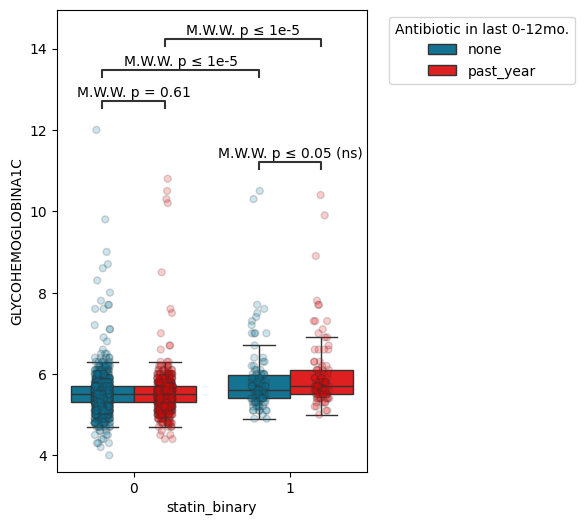

In [64]:
abx_order = ['none', 'past_year']
abx_year_pal = {'none': "#007ea7", 'past_year': 'red'}

statin_order = [0, 1]
comparisons=[
    ((0, 'none'), (0, 'past_year')),
    ((1,'none'),(1, 'past_year')),
    ((0, 'none'), (1, 'none')),
    ((0, 'past_year'), (1, 'past_year')),
    ]

fig, ax = plt.subplots(1, 1, figsize=(4, 6))
sns.boxplot(data=labs_clean_statin, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
            hue='abx_year', showfliers=False, palette=abx_year_pal,
            order=statin_order, hue_order=abx_order)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Antibiotic in last 0-12mo.")

sns.stripplot(data=labs_clean_statin, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
              hue='abx_year',  palette=abx_year_pal, 
              order=statin_order, hue_order=abx_order,
              alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Annotate
annotator = Annotator(ax, comparisons, data=labs_clean_statin, x='statin_binary', y='GLYCOHEMOGLOBINA1C',
               order=statin_order, hue='abx_year', hue_order=abx_order)
annotator.configure(test='Mann-Whitney', verbose=2, comparisons_correction="BH", text_format='simple')
annotator.apply_test() 
annotator.annotate()